In [1]:
import numpy as np

In [2]:
# Original model weight matrix
d = 1000

W = np.random.randn(d, d)

print("Weight matrix shape:", W.shape)
print("Total parameters:", W.size)


Weight matrix shape: (1000, 1000)
Total parameters: 1000000


In [3]:
# Full Fine-Tuning

full_ft_trainable_params = W.size

print("Full Fine-Tuning trainable parameters:",
      full_ft_trainable_params)

Full Fine-Tuning trainable parameters: 1000000


In [4]:
# LoRA rank
r = 4

print("LoRA rank:", r)

LoRA rank: 4


In [5]:
# LoRA matrices

A = np.random.randn(r, d)
B = np.random.randn(d, r)

print("Shape of A:", A.shape)
print("Shape of B:", B.shape)

Shape of A: (4, 1000)
Shape of B: (1000, 4)


In [6]:
# Calculate trainable parameters in LoRA

A_params = A.size
B_params = B.size

lora_trainable_params = A_params + B_params

print("A parameters:", A_params)
print("B parameters:", B_params)
print("Total LoRA trainable parameters:", lora_trainable_params)

A parameters: 4000
B parameters: 4000
Total LoRA trainable parameters: 8000


In [7]:
print("Full Fine-Tuning:", full_ft_trainable_params)
print("LoRA:", lora_trainable_params)

reduction = (
    (full_ft_trainable_params - lora_trainable_params)
    / full_ft_trainable_params
) * 100

print("Reduction in trainable parameters:", reduction, "%")

Full Fine-Tuning: 1000000
LoRA: 8000
Reduction in trainable parameters: 99.2 %


In [8]:
# Calculate LoRA weight update

delta_W = B @ A

print("Original W shape:", W.shape)
print("Delta W shape:", delta_W.shape)

Original W shape: (1000, 1000)
Delta W shape: (1000, 1000)


In [9]:
# Updated weights using LoRA

W_new = W + delta_W

print("Updated W shape:", W_new.shape)

Updated W shape: (1000, 1000)


In [10]:
alpha = 16

W_new_scaled = W + (alpha / r) * delta_W

print("Alpha:", alpha)
print("Rank:", r)
print("Scaling factor:", alpha / r)

Alpha: 16
Rank: 4
Scaling factor: 4.0


In [11]:
# FP16 memory calculation

total_params = W.size

fp16_bits = 16

fp16_memory_bytes = (total_params * fp16_bits) / 8

fp16_memory_mb = fp16_memory_bytes / (1024 ** 2)

print("FP16 memory:", round(fp16_memory_mb, 2), "MB")

FP16 memory: 1.91 MB


In [12]:
# Theoretical 4-bit memory calculation

int4_bits = 4

int4_memory_bytes = (total_params * int4_bits) / 8

int4_memory_mb = int4_memory_bytes / (1024 ** 2)

print("4-bit memory:", round(int4_memory_mb, 2), "MB")

4-bit memory: 0.48 MB


In [13]:
# Memory comparison

print("FP16 memory:", round(fp16_memory_mb, 2), "MB")
print("4-bit memory:", round(int4_memory_mb, 2), "MB")

memory_reduction = (
    (fp16_memory_mb - int4_memory_mb) / fp16_memory_mb
) * 100

print("Memory reduction:", round(memory_reduction, 2), "%")

FP16 memory: 1.91 MB
4-bit memory: 0.48 MB
Memory reduction: 75.0 %


In [14]:
# Final comparison

methods = {
    "Full Fine-Tuning": {
        "trainable_params": full_ft_trainable_params,
        "base_memory_mb": fp16_memory_mb
    },

    "LoRA": {
        "trainable_params": lora_trainable_params,
        "base_memory_mb": fp16_memory_mb
    },

    "QLoRA": {
        "trainable_params": lora_trainable_params,
        "base_memory_mb": int4_memory_mb
    }
}

for method, details in methods.items():
    print("\nMethod:", method)
    print("Trainable parameters:", details["trainable_params"])
    print("Base weight storage:",
          round(details["base_memory_mb"], 2), "MB")


Method: Full Fine-Tuning
Trainable parameters: 1000000
Base weight storage: 1.91 MB

Method: LoRA
Trainable parameters: 8000
Base weight storage: 1.91 MB

Method: QLoRA
Trainable parameters: 8000
Base weight storage: 0.48 MB


In [15]:
# Trainable parameter percentage

for method, details in methods.items():

    percentage = (
        details["trainable_params"] / total_params
    ) * 100

    print(method, ":", round(percentage, 2), "%")

Full Fine-Tuning : 100.0 %
LoRA : 0.8 %
QLoRA : 0.8 %


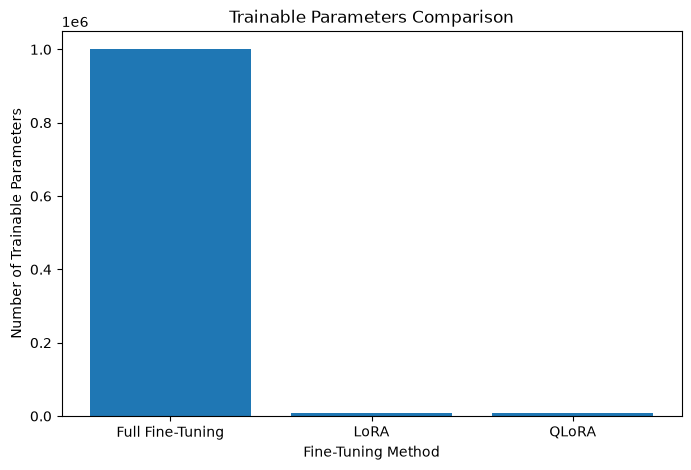

In [16]:
import matplotlib.pyplot as plt

names = list(methods.keys())

trainable = [
    methods[name]["trainable_params"]
    for name in names
]

plt.figure(figsize=(8, 5))

plt.bar(names, trainable)

plt.title("Trainable Parameters Comparison")
plt.xlabel("Fine-Tuning Method")
plt.ylabel("Number of Trainable Parameters")

plt.show()